In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [47]:
data = pd.read_csv("../data/careflow_ed_event_log_as_is.csv")
data

,Case_ID,Activity_Name,Timestamp,Department,Resource,Waiting_Time_Min,Duration_Min,Patient_Type,Triage_Level,Event_Sequence,Is_Revisit,Loop_Back_Flag,Outcome,Scenario,Data_Origin
0,ED-00001,Registration,2026-01-01 00:59:23,Registration,REG-01,0.00,2.80,Walk-in,3,1,0,1,Discharged,AS-IS,SIMULATED
1,ED-00001,Triage,2026-01-01 01:13:13,Triage,TN-01,11.03,2.53,Walk-in,3,2,0,1,Discharged,AS-IS,SIMULATED
2,ED-00001,Doctor Consultation,2026-01-01 02:15:47,Emergency Medicine,DR-05,60.03,13.67,Walk-in,3,3,0,1,Discharged,AS-IS,SIMULATED
3,ED-00001,Lab Test,2026-01-01 02:38:37,Laboratory,LT-03,9.17,6.60,Walk-in,3,4,0,1,Discharged,AS-IS,SIMULATED
4,ED-00001,Lab Result Received,2026-01-01 03:07:23,Laboratory,LT-02,22.17,1.43,Walk-in,3,5,0,1,Discharged,AS-IS,SIMULATED
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,ED-01385,Triage,2026-04-01 00:27:51,Triage,TN-03,29.05,5.87,Walk-in,5,2,0,1,Discharged,AS-IS,SIMULATED
9996,ED-01385,Doctor Consultation,2026-04-01 01:20:35,Emergency Medicine,DR-06,46.87,24.28,Walk-in,5,3,0,1,Discharged,AS-IS,SIMULATED
9997,ED-01385,Doctor Consultation,2026-04-01 02:00:04,Emergency Medicine,DR-03,15.20,8.20,Walk-in,5,4,1,1,Discharged,AS-IS,SIMULATED
9998,ED-01385,Treatment,2026-04-01 02:21:46,Emergency Medicine,TRN-02,13.50,30.00,Walk-in,5,5,0,1,Discharged,AS-IS,SIMULATED


In [48]:
data.head()

,Case_ID,Activity_Name,Timestamp,Department,Resource,Waiting_Time_Min,Duration_Min,Patient_Type,Triage_Level,Event_Sequence,Is_Revisit,Loop_Back_Flag,Outcome,Scenario,Data_Origin
0,ED-00001,Registration,2026-01-01 00:59:23,Registration,REG-01,0.00,2.80,Walk-in,3,1,0,1,Discharged,AS-IS,SIMULATED
1,ED-00001,Triage,2026-01-01 01:13:13,Triage,TN-01,11.03,2.53,Walk-in,3,2,0,1,Discharged,AS-IS,SIMULATED
2,ED-00001,Doctor Consultation,2026-01-01 02:15:47,Emergency Medicine,DR-05,60.03,13.67,Walk-in,3,3,0,1,Discharged,AS-IS,SIMULATED
3,ED-00001,Lab Test,2026-01-01 02:38:37,Laboratory,LT-03,9.17,6.60,Walk-in,3,4,0,1,Discharged,AS-IS,SIMULATED
4,ED-00001,Lab Result Received,2026-01-01 03:07:23,Laboratory,LT-02,22.17,1.43,Walk-in,3,5,0,1,Discharged,AS-IS,SIMULATED


In [49]:
data.shape

(10000, 15)

In [50]:
data.columns

Index(['Case_ID', 'Activity_Name', 'Timestamp', 'Department', 'Resource',
       'Waiting_Time_Min', 'Duration_Min', 'Patient_Type', 'Triage_Level',
       'Event_Sequence', 'Is_Revisit', 'Loop_Back_Flag', 'Outcome', 'Scenario',
       'Data_Origin'],
      dtype='object')

In [51]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Case_ID           10000 non-null  object 
 1   Activity_Name     10000 non-null  object 
 2   Timestamp         10000 non-null  object 
 3   Department        10000 non-null  object 
 4   Resource          10000 non-null  object 
 5   Waiting_Time_Min  10000 non-null  float64
 6   Duration_Min      10000 non-null  float64
 7   Patient_Type      10000 non-null  object 
 8   Triage_Level      10000 non-null  int64  
 9   Event_Sequence    10000 non-null  int64  
 10  Is_Revisit        10000 non-null  int64  
 11  Loop_Back_Flag    10000 non-null  int64  
 12  Outcome           10000 non-null  object 
 13  Scenario          10000 non-null  object 
 14  Data_Origin       10000 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 1.1+ MB


In [52]:
data.describe(include="all")

,Case_ID,Activity_Name,Timestamp,Department,Resource,Waiting_Time_Min,Duration_Min,Patient_Type,Triage_Level,Event_Sequence,Is_Revisit,Loop_Back_Flag,Outcome,Scenario,Data_Origin
count,10000,10000,10000,10000,10000,10000.000000,10000.000000,10000,10000.000000,10000.000000,10000.0000,10000.000000,10000,10000,10000
unique,1385,9,9992,7,31,NaN,NaN,3,NaN,NaN,NaN,NaN,2,1,1
top,ED-00029,Doctor Consultation,2026-01-25 12:19:44,Emergency Medicine,DN-02,NaN,NaN,Walk-in,NaN,NaN,NaN,NaN,Discharged,AS-IS,SIMULATED
freq,12,2026,2,3411,601,NaN,NaN,7064,NaN,NaN,NaN,NaN,8268,10000,10000
mean,NaN,NaN,NaN,NaN,NaN,27.880757,12.415851,NaN,3.074400,4.325600,0.0982,0.475100,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,43.836340,13.714858,NaN,0.986084,2.424082,0.2976,0.499405,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,0.000000,0.520000,NaN,1.000000,1.000000,0.0000,0.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,5.245000,4.565000,NaN,2.000000,2.000000,0.0000,0.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,13.630000,8.270000,NaN,3.000000,4.000000,0.0000,0.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,32.900000,14.970000,NaN,4.000000,6.000000,0.0000,1.000000,NaN,NaN,NaN


In [53]:
data.dtypes

Case_ID              object
Activity_Name        object
Timestamp            object
Department           object
Resource             object
Waiting_Time_Min    float64
Duration_Min        float64
Patient_Type         object
Triage_Level          int64
Event_Sequence        int64
Is_Revisit            int64
Loop_Back_Flag        int64
Outcome              object
Scenario             object
Data_Origin          object
dtype: object

In [54]:
df = data.copy()


In [55]:
df.head()


,Case_ID,Activity_Name,Timestamp,Department,Resource,Waiting_Time_Min,Duration_Min,Patient_Type,Triage_Level,Event_Sequence,Is_Revisit,Loop_Back_Flag,Outcome,Scenario,Data_Origin
0,ED-00001,Registration,2026-01-01 00:59:23,Registration,REG-01,0.00,2.80,Walk-in,3,1,0,1,Discharged,AS-IS,SIMULATED
1,ED-00001,Triage,2026-01-01 01:13:13,Triage,TN-01,11.03,2.53,Walk-in,3,2,0,1,Discharged,AS-IS,SIMULATED
2,ED-00001,Doctor Consultation,2026-01-01 02:15:47,Emergency Medicine,DR-05,60.03,13.67,Walk-in,3,3,0,1,Discharged,AS-IS,SIMULATED
3,ED-00001,Lab Test,2026-01-01 02:38:37,Laboratory,LT-03,9.17,6.60,Walk-in,3,4,0,1,Discharged,AS-IS,SIMULATED
4,ED-00001,Lab Result Received,2026-01-01 03:07:23,Laboratory,LT-02,22.17,1.43,Walk-in,3,5,0,1,Discharged,AS-IS,SIMULATED


In [56]:
data.isna().sum()

Case_ID             0
Activity_Name       0
Timestamp           0
Department          0
Resource            0
Waiting_Time_Min    0
Duration_Min        0
Patient_Type        0
Triage_Level        0
Event_Sequence      0
Is_Revisit          0
Loop_Back_Flag      0
Outcome             0
Scenario            0
Data_Origin         0
dtype: int64

In [57]:
data.duplicated().sum()

np.int64(0)

In [58]:
data[data.duplicated()]

,Case_ID,Activity_Name,Timestamp,Department,Resource,Waiting_Time_Min,Duration_Min,Patient_Type,Triage_Level,Event_Sequence,Is_Revisit,Loop_Back_Flag,Outcome,Scenario,Data_Origin


In [59]:
data[data[['Case_ID', 'Activity_Name', 'Timestamp']].duplicated()]

,Case_ID,Activity_Name,Timestamp,Department,Resource,Waiting_Time_Min,Duration_Min,Patient_Type,Triage_Level,Event_Sequence,Is_Revisit,Loop_Back_Flag,Outcome,Scenario,Data_Origin


In [60]:
data.nunique()

Case_ID             1385
Activity_Name          9
Timestamp           9992
Department             7
Resource              31
Waiting_Time_Min    3700
Duration_Min        2263
Patient_Type           3
Triage_Level           5
Event_Sequence        12
Is_Revisit             2
Loop_Back_Flag         2
Outcome                2
Scenario               1
Data_Origin            1
dtype: int64

In [61]:
data['Case_ID'].nunique()

1385

In [62]:
data['Activity_Name'].nunique()

9

In [63]:
data['Case_ID'].value_counts()

Case_ID
ED-00029    12
ED-01333    12
ED-01133    12
ED-00694    12
ED-00172    12
            ..
ED-00060     5
ED-01341     5
ED-01338     5
ED-00874     5
ED-00871     5
Name: count, Length: 1385, dtype: int64

In [64]:
data['Activity_Name'].value_counts()

Activity_Name
Doctor Consultation    2026
Triage                 1508
Registration           1385
Treatment              1385
Discharge              1164
Lab Result Received     819
Lab Test                819
X-Ray                   673
Admission               221
Name: count, dtype: int64

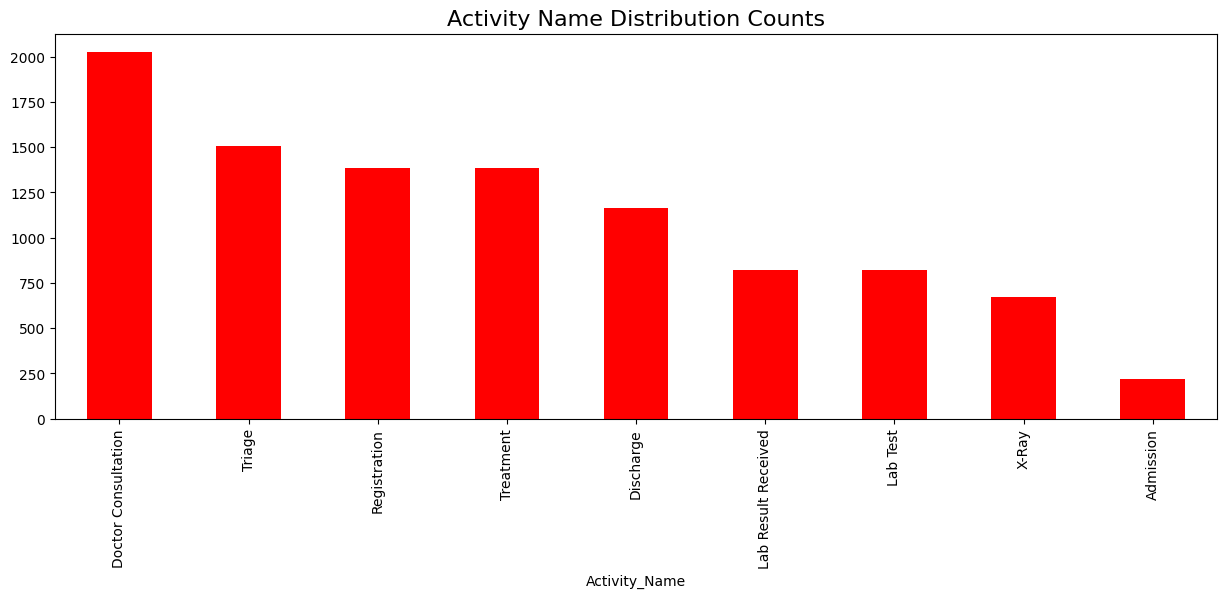

In [65]:
data['Activity_Name'].value_counts().plot(kind='bar', figsize=(15, 5), color='red')
plt.title('Activity Name Distribution Counts', fontsize=16)
plt.show()

In [66]:
df.dtypes

Case_ID              object
Activity_Name        object
Timestamp            object
Department           object
Resource             object
Waiting_Time_Min    float64
Duration_Min        float64
Patient_Type         object
Triage_Level          int64
Event_Sequence        int64
Is_Revisit            int64
Loop_Back_Flag        int64
Outcome              object
Scenario             object
Data_Origin          object
dtype: object

In [67]:
df.head(3)

,Case_ID,Activity_Name,Timestamp,Department,Resource,Waiting_Time_Min,Duration_Min,Patient_Type,Triage_Level,Event_Sequence,Is_Revisit,Loop_Back_Flag,Outcome,Scenario,Data_Origin
0,ED-00001,Registration,2026-01-01 00:59:23,Registration,REG-01,0.00,2.80,Walk-in,3,1,0,1,Discharged,AS-IS,SIMULATED
1,ED-00001,Triage,2026-01-01 01:13:13,Triage,TN-01,11.03,2.53,Walk-in,3,2,0,1,Discharged,AS-IS,SIMULATED
2,ED-00001,Doctor Consultation,2026-01-01 02:15:47,Emergency Medicine,DR-05,60.03,13.67,Walk-in,3,3,0,1,Discharged,AS-IS,SIMULATED


In [68]:
df.columns = df.columns.str.lower()

In [69]:
df = df.rename(columns={'is_revisit': 'activity_repeated'})

In [70]:
df.columns

Index(['case_id', 'activity_name', 'timestamp', 'department', 'resource',
       'waiting_time_min', 'duration_min', 'patient_type', 'triage_level',
       'event_sequence', 'activity_repeated', 'loop_back_flag', 'outcome',
       'scenario', 'data_origin'],
      dtype='object')

In [71]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="ignore"
    
)

df["timestamp"].dtypes

C:\Users\Admin\AppData\Local\Temp\ipykernel_19732\702797771.py:1: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  df["timestamp"] = pd.to_datetime(


dtype('<M8[ns]')

In [72]:
print(df["timestamp"].dtypes)

datetime64[ns]


In [73]:
print((df['waiting_time_min'] == 0).sum())

1385


In [74]:
print("Negative waiting times:",
      (df["waiting_time_min"] < 0).sum())

print("Negative durations:",
      (df["duration_min"] < 0).sum())

print("Zero waiting times:",
      (df["waiting_time_min"] == 0).sum())

print("Zero durations:",
      (df["duration_min"] == 0).sum())

Negative waiting times: 0
Negative durations: 0
Zero waiting times: 1385
Zero durations: 0


In [75]:
events_per_patient = (
    df.groupby("case_id")["activity_name"].count()
)

events_per_patient.head(10)

case_id
ED-00001     8
ED-00002     6
ED-00003     7
ED-00004    10
ED-00005    10
ED-00006     5
ED-00007     7
ED-00008     7
ED-00009     7
ED-00010     7
Name: activity_name, dtype: int64

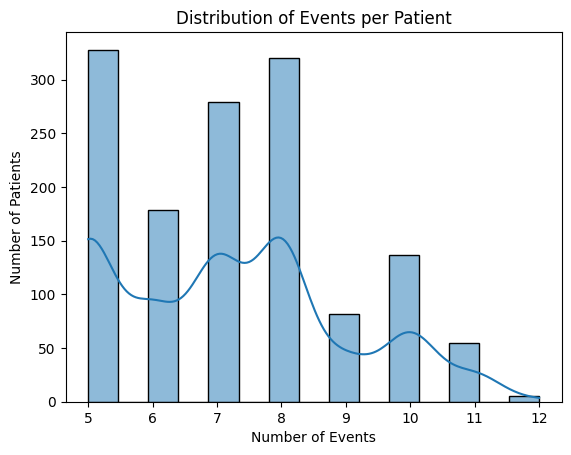

In [76]:
plt.Figure(figsize=(10,6))

sns.histplot(events_per_patient, bins=15, kde=True)

plt.title("Distribution of Events per Patient")
plt.xlabel("Number of Events")
plt.ylabel("Number of Patients")

plt.show()

In [77]:
# df_work = df_work.sort_values(
#     by=["Case_ID", "Timestamp"]
# ).reset_index(drop=True)

# df_work.head(10)

# Will order it Chronologically by Case_ID and Timestamp, cause process mining depends on the order in which event happen 

In [78]:
patient_journeys = (
    df.groupby("case_id")["activity_name"]
    .apply(list)
)

patient_journeys.head(10)

case_id
ED-00001    [Registration, Triage, Doctor Consultation, La...
ED-00002    [Registration, Triage, Doctor Consultation, X-...
ED-00003    [Registration, Triage, Doctor Consultation, La...
ED-00004    [Registration, Triage, Doctor Consultation, La...
ED-00005    [Registration, Triage, Doctor Consultation, La...
ED-00006    [Registration, Triage, Doctor Consultation, Tr...
ED-00007    [Registration, Triage, Doctor Consultation, X-...
ED-00008    [Registration, Triage, Doctor Consultation, La...
ED-00009    [Registration, Triage, Doctor Consultation, La...
ED-00010    [Registration, Triage, Doctor Consultation, La...
Name: activity_name, dtype: object

In [79]:
case_id = "ED-00001"

individual_patient_data = df[df["case_id"] == case_id]

display(individual_patient_data[
        [
            "case_id",
            "activity_name",
            "timestamp",
            "waiting_time_min",
            "duration_min"
        ]
    ]
)

,case_id,activity_name,timestamp,waiting_time_min,duration_min
0,ED-00001,Registration,2026-01-01 00:59:23,0.00,2.80
1,ED-00001,Triage,2026-01-01 01:13:13,11.03,2.53
2,ED-00001,Doctor Consultation,2026-01-01 02:15:47,60.03,13.67
3,ED-00001,Lab Test,2026-01-01 02:38:37,9.17,6.60
4,ED-00001,Lab Result Received,2026-01-01 03:07:23,22.17,1.43
5,ED-00001,Doctor Consultation,2026-01-01 03:32:56,24.12,12.08
6,ED-00001,Treatment,2026-01-01 03:59:34,14.55,24.80
7,ED-00001,Discharge,2026-01-01 04:27:58,3.60,9.17


In [80]:
case_id = "ED-00101"

patient_data = df[df["case_id"] == case_id]

display(patient_data[
        [
            "case_id",
            "activity_name",
            "timestamp",
            "waiting_time_min",
            "duration_min"
        ]
    ]
)

,case_id,activity_name,timestamp,waiting_time_min,duration_min
760,ED-00101,Registration,2026-01-07 12:46:25,0.00,2.22
761,ED-00101,Triage,2026-01-07 12:58:38,10.00,2.92
762,ED-00101,Doctor Consultation,2026-01-07 14:58:47,117.23,13.23
763,ED-00101,Lab Test,2026-01-07 15:22:10,10.15,5.13
764,ED-00101,Lab Result Received,2026-01-07 16:10:57,43.65,1.23
765,ED-00101,X-Ray,2026-01-07 17:26:21,74.17,12.42
766,ED-00101,Treatment,2026-01-07 17:47:18,8.53,47.75
767,ED-00101,Discharge,2026-01-07 18:40:52,5.82,8.35


In [81]:
waiting_analysis = (
    df.groupby("activity_name")["waiting_time_min"].agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

waiting_analysis

,count,mean
activity_name,,
Doctor Consultation,2026,65.411436
Lab Result Received,819,54.994042
Admission,221,44.448552
X-Ray,673,38.185542
Discharge,1164,19.905902
Treatment,1385,14.837025
Lab Test,819,10.425543
Triage,1508,8.928123
Registration,1385,0.000000


In [82]:
repeated_activities = (
    df.groupby(["case_id", "activity_name", "waiting_time_min"]).size().reset_index(name="activity_count")
)

repeated_activities = repeated_activities[
    repeated_activities["activity_count"] > 1
]

print(repeated_activities.head(10))

Empty DataFrame
Columns: [case_id, activity_name, waiting_time_min, activity_count]
Index: []


In [83]:
df.head()

,case_id,activity_name,timestamp,department,resource,waiting_time_min,duration_min,patient_type,triage_level,event_sequence,activity_repeated,loop_back_flag,outcome,scenario,data_origin
0,ED-00001,Registration,2026-01-01 00:59:23,Registration,REG-01,0.00,2.80,Walk-in,3,1,0,1,Discharged,AS-IS,SIMULATED
1,ED-00001,Triage,2026-01-01 01:13:13,Triage,TN-01,11.03,2.53,Walk-in,3,2,0,1,Discharged,AS-IS,SIMULATED
2,ED-00001,Doctor Consultation,2026-01-01 02:15:47,Emergency Medicine,DR-05,60.03,13.67,Walk-in,3,3,0,1,Discharged,AS-IS,SIMULATED
3,ED-00001,Lab Test,2026-01-01 02:38:37,Laboratory,LT-03,9.17,6.60,Walk-in,3,4,0,1,Discharged,AS-IS,SIMULATED
4,ED-00001,Lab Result Received,2026-01-01 03:07:23,Laboratory,LT-02,22.17,1.43,Walk-in,3,5,0,1,Discharged,AS-IS,SIMULATED


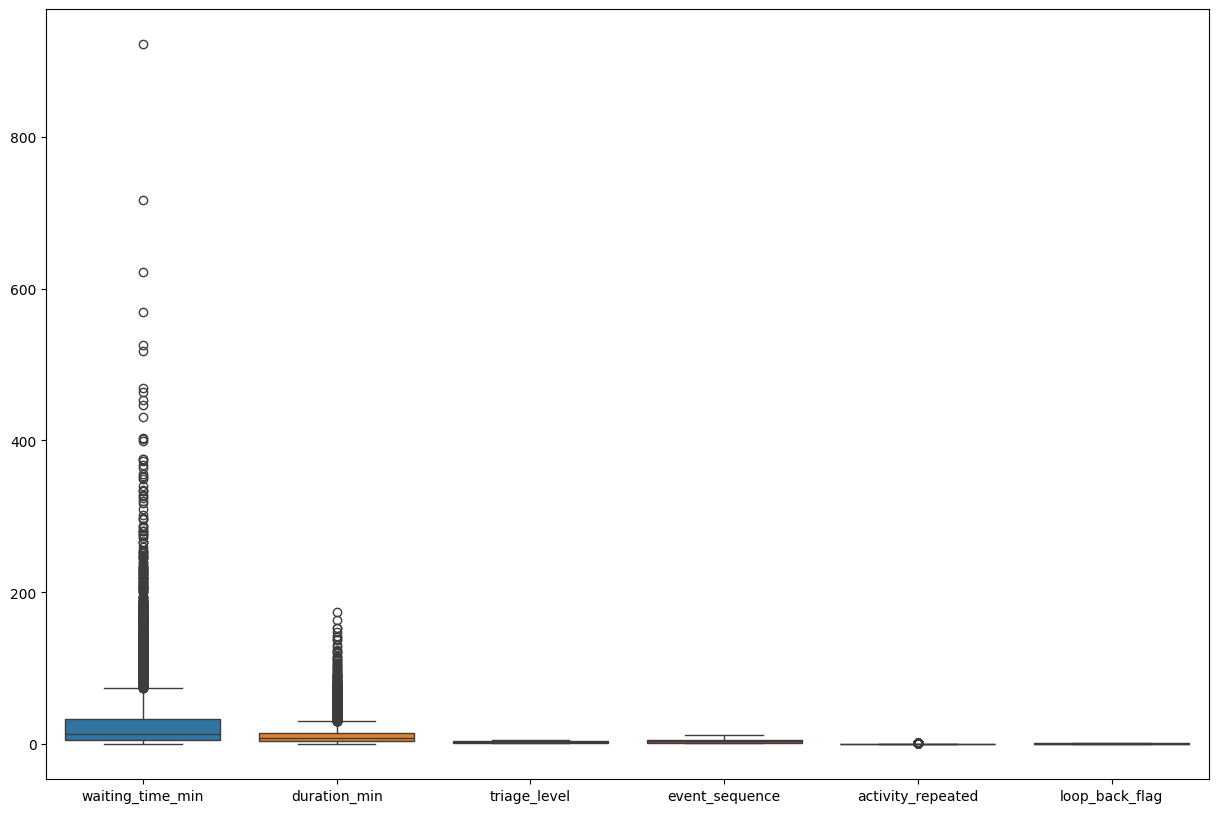

In [84]:
plt.figure(figsize=(15,10))
sns.boxplot(df)
plt.show()

In [87]:
# mean_wait_by_activity = (
#     data.groupby("activity_name")["waiting_time_min"].mean().sort_values
# )

# fig, ax = plt.subplots(figsize=(10, 6))
# bars = ax.barh(mean_wait_by_activity.index, mean_wait_by_activity.values, color="#2a7f9e")
# ax.bar_label(bars, fmt="%.1f min", padding=4)
# ax.set_title("Average Waiting Time by Emergency Department Activity")
# ax.set_xlabel("Average waiting time (minutes)")
# ax.set_ylabel("Activity")
# ax.set_xlim(0, mean_wait_by_activity.max() * 1.18)
# ax.grid(axis="x", linestyle="--", alpha=0.35)
# ax.set_axisbelow(True)
# plt.tight_layout()
# plt.show()

In [90]:
df.head(3)

,case_id,activity_name,timestamp,department,resource,waiting_time_min,duration_min,patient_type,triage_level,event_sequence,activity_repeated,loop_back_flag,outcome,scenario,data_origin
0,ED-00001,Registration,2026-01-01 00:59:23,Registration,REG-01,0.00,2.80,Walk-in,3,1,0,1,Discharged,AS-IS,SIMULATED
1,ED-00001,Triage,2026-01-01 01:13:13,Triage,TN-01,11.03,2.53,Walk-in,3,2,0,1,Discharged,AS-IS,SIMULATED
2,ED-00001,Doctor Consultation,2026-01-01 02:15:47,Emergency Medicine,DR-05,60.03,13.67,Walk-in,3,3,0,1,Discharged,AS-IS,SIMULATED


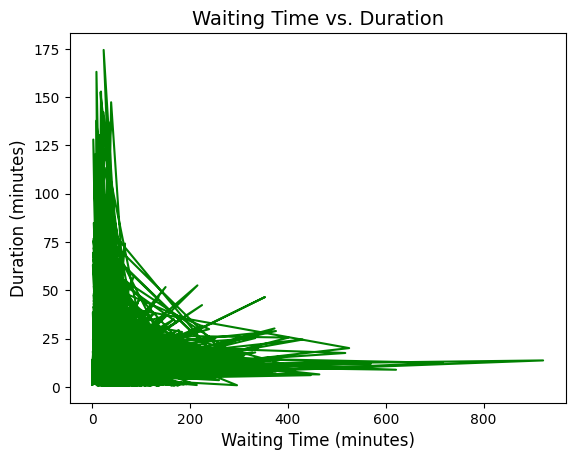

In [97]:
plt.plot(df['waiting_time_min'], df['duration_min'], color='green')
plt.xlabel('Waiting Time (minutes)', fontsize=12)
plt.ylabel('Duration (minutes)', fontsize=12)
plt.title('Waiting Time vs. Duration', fontsize=14)
plt.show()

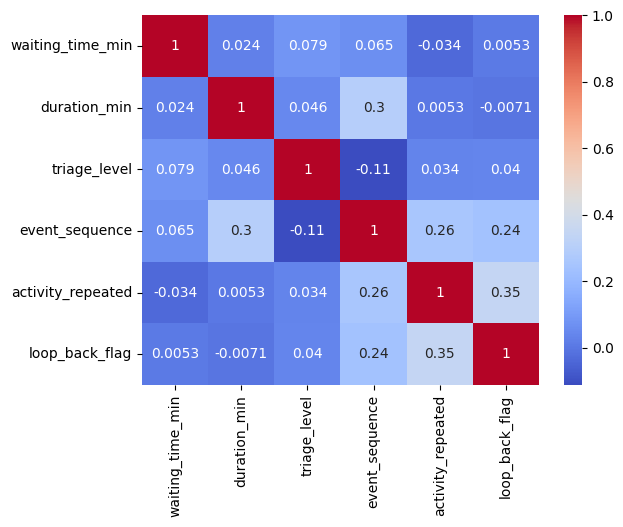

In [100]:
df_corr = df.corr(numeric_only=True)

sns.heatmap(df_corr, annot=True, fmt=".2g", cmap="coolwarm", )
plt.show()